# 004 · Engenharia de variáveis

**Objetivo:** transformar `jogador_temporada.csv` na base de modelagem: definir o alvo (valor de mercado em log) e criar as variáveis derivadas.

**Entrada:** `data/processado/jogador_temporada.csv` e `jogos_brasileirao.csv`  
**Saída:** `data/processado/features_modelo.csv`

In [1]:
import sys
sys.path.append("../scripts")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from engenharia_features import montar_features

jogador_temporada = pd.read_csv("../data/processado/jogador_temporada.csv")
jogos_brasileirao = pd.read_csv("../data/processado/jogos_brasileirao.csv")

In [2]:
print(jogos_brasileirao.shape)
jogos_brasileirao.head()

(557, 23)


,game_id,competition_id,season,round,date,home_club_id,away_club_id,home_club_goals,away_club_goals,home_club_position,...,stadium,attendance,referee,url,home_club_formation,away_club_formation,home_club_name,away_club_name,aggregate,competition_type
0,4582030,BRA1,2024,3. Matchday,2025-04-13,2462,221,1,0,5.0,...,Estádio Jornalista Mário Filho,46172.0,Felipe Fernandes de Lima,https://www.transfermarkt.co.uk/fluminense-foo...,4-2-3-1,4-2-3-1,Fluminense Football Club,Santos Futebol Clube,1:0,domestic_league
1,4582031,BRA1,2024,3. Matchday,2025-04-13,978,8718,3,1,4.0,...,Estádio São Januário,15969.0,Wilton Pereira Sampaio,https://www.transfermarkt.co.uk/clube-de-regat...,4-2-3-1,4-5-1,Club de Regatas Vasco da Gama,Sport Club do Recife,3:1,domestic_league
2,4582032,BRA1,2024,3. Matchday,2025-04-12,1023,199,2,0,2.0,...,Arena Barueri,19297.0,Rafael Rodrigo Klein,https://www.transfermarkt.co.uk/sociedade-espo...,3-4-2-1,4-3-1-2,Sociedade Esportiva Palmeiras,Sport Club Corinthians Paulista,2:0,domestic_league
3,4582033,BRA1,2024,3. Matchday,2025-04-13,585,609,1,1,15.0,...,MorumBIS,37566.0,Rodrigo José Pereira de Lima,https://www.transfermarkt.co.uk/sao-paulo-fute...,4-2-3-1,4-2-3-1,São Paulo Futebol Clube,Cruzeiro Esporte Clube,1:1,domestic_league
4,4582034,BRA1,2024,3. Matchday,2025-04-12,8793,537,1,0,11.0,...,Estádio Nabi Abi Chedid,5233.0,Anderson Daronco,https://www.transfermarkt.co.uk/red-bull-braga...,4-2-3-1,4-2-3-1,Red Bull Bragantino,S. A. F. Botafogo,1:0,domestic_league


In [3]:
print(jogador_temporada.shape)
jogador_temporada.head()

(507, 25)


,season,player_id,gols,assistencias,minutos_jogados,cartoes_amarelos,cartoes_vermelhos,jogos_disputados,temporada_completa,gols_por90,...,position,sub_position,foot,height_in_cm,date_of_birth,country_of_citizenship,current_club_name,contract_expiration_date,idade,market_value_in_eur
0,2024,22415,0,0,3420,2,0,38,True,0.000000,...,Goalkeeper,Goalkeeper,right,188.0,1980-09-30 00:00:00,Brazil,Fluminense Football Club,2027-12-31 00:00:00,44.9,100000.0
1,2024,29091,3,4,1008,3,0,25,True,0.267857,...,Midfield,Attacking Midfield,left,181.0,1981-07-19 00:00:00,Brazil,Esporte Clube Juventude,NaN,44.1,200000.0
2,2024,29241,2,0,2158,1,0,25,True,0.083411,...,Defender,Centre-Back,right,181.0,1984-09-22 00:00:00,Brazil,Fluminense Football Club,2026-12-31 00:00:00,40.9,700000.0
3,2024,45319,1,0,1195,4,0,14,True,0.075314,...,Defender,Centre-Back,right,180.0,1987-03-18 00:00:00,Argentina,Sport Club Internacional,2026-12-31 00:00:00,38.6,200000.0
4,2024,50144,0,0,3087,5,0,35,True,0.000000,...,Goalkeeper,Goalkeeper,left,196.0,1987-06-06 00:00:00,Brazil,Cruzeiro Esporte Clube,2027-05-31 00:00:00,38.2,300000.0


## Alvo: valor de mercado

Pela EDA descobrimos que o valor de mercado é muito assimétrico, poucos jogadores valem muito mais que a maioria. Por isso o alvo escolhido foi o log do valor

Jogadores sem valor de mercado registrado não entram na base de modelagem (32 como mostrado no EDA).

Assimetria: original = 1.76 | log = -0.42


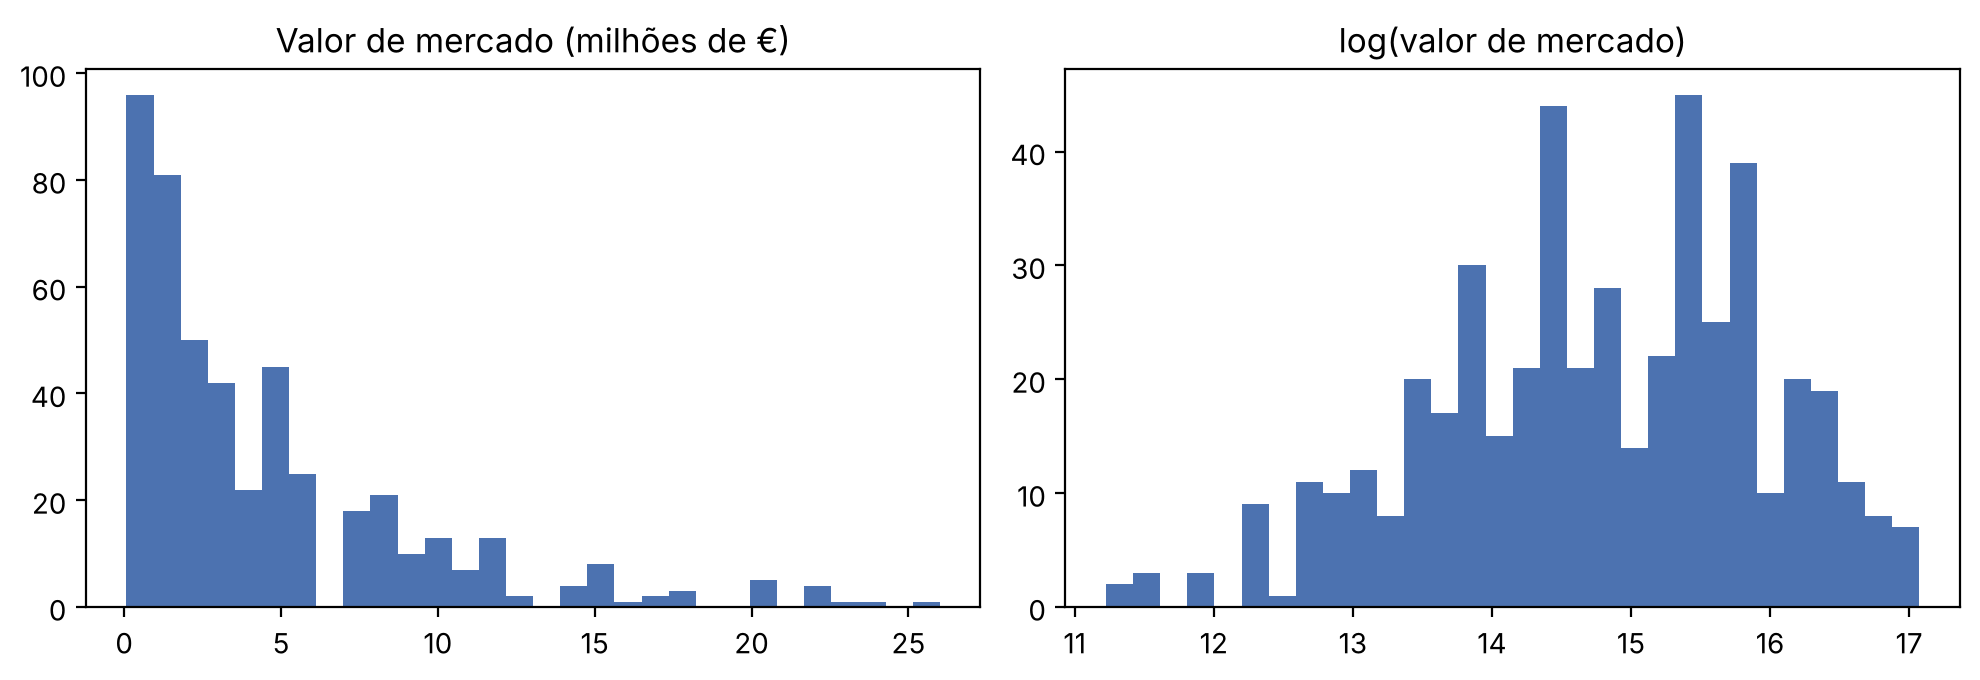

In [4]:
valor = jogador_temporada["market_value_in_eur"].dropna()

fig, eixos = plt.subplots(1, 2, figsize=(10, 3.5))
eixos[0].hist(valor / 1e6, bins=30, color="#4C72B0")
eixos[0].set_title("Valor de mercado (milhões de €)")
eixos[1].hist(np.log(valor), bins=30, color="#4C72B0")
eixos[1].set_title("log(valor de mercado)")
plt.tight_layout()

fig.savefig("../figuras/features_alvo_log.png")
print(f"Assimetria: original = {valor.skew():.2f} | log = {np.log(valor).skew():.2f}")

## Variáveis criadas

- `idade2`: idade ao quadrado.
- `faixa_idade`: faixas de idade (até 21, 22–25, 26–29, 30–33, 34+).
- `eh_estrangeiro`: 1 se não for brasileiro.
- `pos_*` e `pe_*`: posição e pé preferencial em 0/1.
- `anos_para_fim_contrato`: anos entre o último jogo da temporada e o fim do contrato.
- `sem_info_contrato`: 1 se o contrato não está informado.

Gols, assistências e cartões por 90 minutos já vieram da seleção de dados.

In [5]:
features = montar_features(jogador_temporada, jogos_brasileirao)
print(features.shape)
features.head()

(475, 28)


,season,player_id,name,clube_temporada,temporada_completa,posicao,faixa_idade,valor_mercado_eur,log_valor_mercado,idade,...,pe_esquerdo,pe_direito,gols_por90,assistencias_por90,cartoes_amarelos_por90,cartoes_vermelhos_por90,minutos_jogados,jogos_disputados,anos_para_fim_contrato,sem_info_contrato
0,2024,22415,Fábio,Fluminense Football Club,True,Goalkeeper,34_mais,100000.0,11.512925,44.9,...,0,1,0.000000,0.000000,0.052632,0.0,3420,38,2.064339,0
1,2024,29091,Nenê,Esporte Clube Juventude,True,Midfield,34_mais,200000.0,12.206073,44.1,...,1,0,0.267857,0.357143,0.267857,0.0,1008,25,NaN,1
2,2024,29241,Thiago Silva,Fluminense Football Club,True,Defender,34_mais,700000.0,13.458836,40.9,...,0,1,0.083411,0.000000,0.041705,0.0,2158,25,1.065024,0
3,2024,45319,Gabriel Mercado,Sport Club Internacional,True,Defender,34_mais,200000.0,12.206073,38.6,...,0,1,0.075314,0.000000,0.301255,0.0,1195,14,1.065024,0
4,2024,50144,Cássio,Cruzeiro Esporte Clube,True,Goalkeeper,34_mais,300000.0,12.611538,38.2,...,1,0,0.000000,0.000000,0.145773,0.0,3087,35,1.478439,0


## Checagens

In [6]:
assert not features.duplicated(["season", "player_id"]).any(), "linhas duplicadas por jogador/temporada"
assert features["log_valor_mercado"].notna().all()

nulos = features.isna().sum()
print("Colunas com nulos:")
print(nulos[nulos > 0].to_string())
print()
print("Linhas por temporada (temporada_completa):")
print(features.groupby("season").agg(linhas=("player_id", "size"), completa=("temporada_completa", "first")).to_string())
print()
print("Jogadores presentes nas duas temporadas:", (features["player_id"].value_counts() > 1).sum())

Colunas com nulos:
anos_para_fim_contrato    7

Linhas por temporada (temporada_completa):


        linhas  completa
season                  
2024       311      True
2025       164     False

Jogadores presentes nas duas temporadas: 117


- 7 jogadores sem contrato informado, por isso vamos preencher com a mediana só com dados de treino e marcar com sem_info_contrato.
- 2025 tem só 164 linhas e é incompleta, por isso vamos usá-la como teste  e treinar em 2024.
- 117 jogadores aparecem nas duas temporadas, por isso vamos validar com GroupKFold por player_id, para o mesmo jogador não ficar em treino e teste ao mesmo tempo.

In [7]:
features.to_csv("../data/processado/features_modelo.csv", index=False)